# Регрессионный анализ зарплат: сравнение моделей на исходных признаках и на главных компонентах

**Целевая переменная:** `Salary` (числовая) — используются линейная, лассо и гребневая регрессии.

**Модули проекта** находятся в папке `src/`.

## 1 Введение

**Цель работы** — построить и сравнить регрессионные модели (линейную, лассо и гребневую) на исходном наборе признаков и на главных компонентах, полученных методом PCA, а также оценить влияние устранения мультиколлинеарности на качество прогноза.

**Задачи:**
1. Описать датасет, визуализировать распределения признаков и корреляционную матрицу.
2. Выполнить предобработку: обработка пропусков, кодирование категориальных признаков, стандартизация, разделение на train/test.
3. Построить линейную, лассо и гребневую регрессии на исходных признаках; рассчитать RMSE, R², MAPE; провести кросс-валидацию и проверить остатки на гомоскедастичность.
4. Устранить мультиколлинеарность с помощью PCA и визуализировать график каменистой осыпи.
5. Повторить построение моделей на главных компонентах и сравнить метрики с исходными.

## 2 Описание датасета

Загружаем датасет `salary_data.csv` через модуль `csv_to_dataframe`. Дополнительно очищаем случайные полностью пустые строки, которые встречаются в исходном файле.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath("src"))

import pandas as pd
from IPython.display import Image, display, Markdown

import csv_to_dataframe as ctd
import dataset_description as dd
import describe_whole as dc
import describes as ds
import plots as pl
import regression_models as rm
import pca_analysis as pa
import heteroscedasticity as hs
import model_comparison as mc

TARGET = "Salary"
MAX_CATEGORIES = 10
PCA_VARIANCE_THRESHOLD = 0.95
PCA_MAX_COMPONENTS = 10
TEST_RATIO = 0.2
CV_FOLDS = 5

data = ctd.csv_to_dataframe("salary_data.csv")
data = data.dropna(how="all").reset_index(drop=True)
data = data.dropna().reset_index(drop=True)

print(f"Размер после очистки: {data.shape}")
data.head()

Размер после очистки: (6698, 6)


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


Датасет содержит смешанные типы признаков: числовые (`Age`, `Years of Experience`, `Salary`) и категориальные (`Gender`, `Education Level`, `Job Title`). Строки с полностью отсутствующими значениями и строки с любыми пропусками удалены — это обеспечивает корректность дальнейшего обучения моделей.

Формируем объект `DatasetDescription`, который содержит размер датасета, типы признаков, количество пропусков, описательные статистики по числовым признакам и матрицу корреляций. Ниже выводим только сводную информацию в виде компактных таблиц, чтобы не перегружать вывод ноутбука.

In [2]:
description = dd.DatasetDescription(data)

shape_df = pd.DataFrame({
    "Показатель": ["Количество строк", "Количество столбцов"],
    "Значение": [description.shape[0], description.shape[1]],
}).set_index("Показатель")

dtypes_df = pd.DataFrame({
    "Признак": description.dtypes.index,
    "Тип": description.dtypes.astype(str).values,
    "Пропусков": description.missing_values.values,
}).set_index("Признак")

numeric_summary = description.numeric_summary.round(2)
categorical_counts = pd.DataFrame({
    col: data[col].value_counts().head(10)
    for col in description.categorical_columns
})

display(shape_df)
display(dtypes_df)
display(numeric_summary)
display(categorical_counts)

,Значение
Показатель,
Количество строк,6698
Количество столбцов,6


,Тип,Пропусков
Признак,,
Age,float64,0
Gender,str,0
Education Level,str,0
Job Title,str,0
Years of Experience,float64,0
Salary,float64,0


,count,mean,std,min,25%,50%,75%,max
Age,6698.0,33.62,7.62,21.0,28.0,32.0,38.0,62.0
Years of Experience,6698.0,8.10,6.06,0.0,3.0,7.0,12.0,34.0
Salary,6698.0,115329.25,52789.79,350.0,70000.0,115000.0,160000.0,250000.0


,Gender,Education Level,Job Title
Bachelor's,NaN,756.0,NaN
Bachelor's Degree,NaN,2265.0,NaN
Back end Developer,NaN,NaN,244.0
Data Analyst,NaN,NaN,363.0
Data Scientist,NaN,NaN,453.0
Female,3013.0,NaN,NaN
Full Stack Engineer,NaN,NaN,308.0
High School,NaN,448.0,NaN
Male,3671.0,NaN,NaN
Marketing Manager,NaN,NaN,255.0


В датасете несколько тысяч наблюдений и всего шесть столбцов. Пропусков нет — они были удалены на этапе загрузки. Числовые признаки непрерывны, категориальные — с ограниченным числом значений, при этом `Job Title` обладает наибольшей кардинальностью (десятки–сотни уникальных значений).

Строим графики распределения числовых признаков: для каждого столбца — гистограмма с оценкой плотности (KDE).

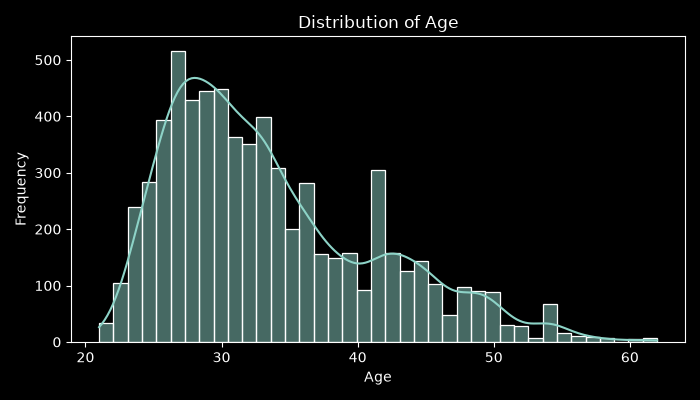

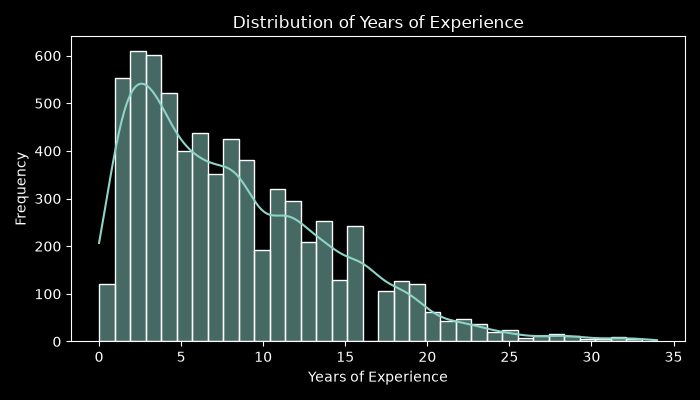

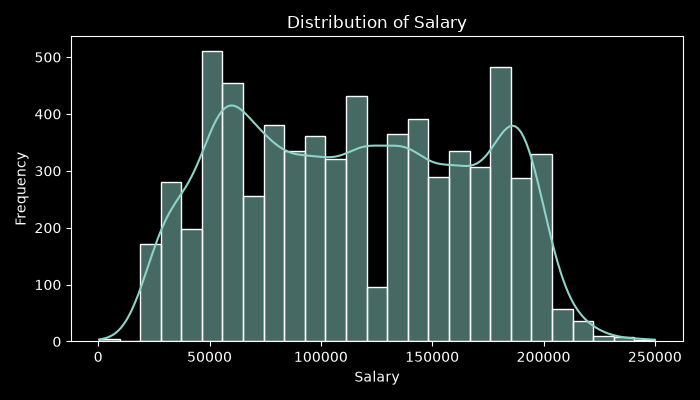

In [3]:
numeric_paths = pl.plot_numeric_distributions(data, description.numeric_columns)
for p in numeric_paths:
    display(Image(filename=p))

Распределения `Age` и `Years of Experience` близки к равномерному с лёгким смещением в сторону молодых сотрудников. `Salary` имеет заметную правостороннюю асимметрию с длинным хвостом высоких значений (руководители, директора). Асимметрия целевой переменной важна: линейные модели чувствительны к масштабу и к выбросам, поэтому стандартизация признаков и целевой переменной обязательна.

Строим графики распределения категориальных признаков (топ-15 значений по частоте).

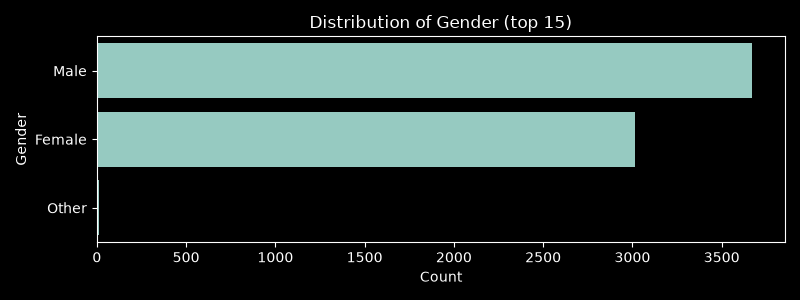

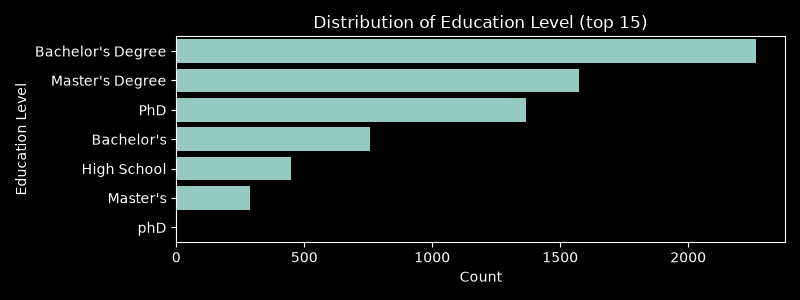

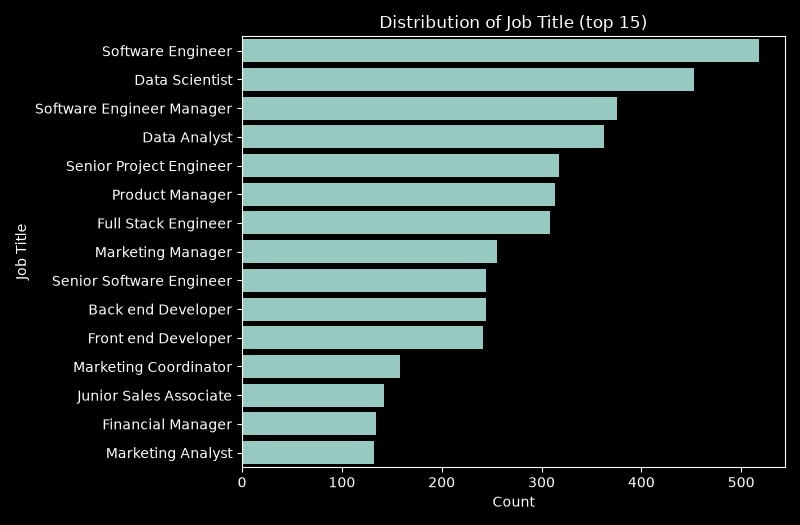

In [4]:
cat_paths = pl.plot_categorical_distributions(data, description.categorical_columns)
for p in cat_paths:
    display(Image(filename=p))

Признаки `Gender` и `Education Level` имеют низкую кардинальность и несбалансированность (преобладают мужчины и обладатели степени бакалавра). `Job Title` — высококардинальный признак; при one-hot-кодировании это породит сотни разреженных столбцов, поэтому далее редкие категории группируются в `"Other"` (топ-10 по частоте).

Строим корреляционную матрицу числовых признаков.

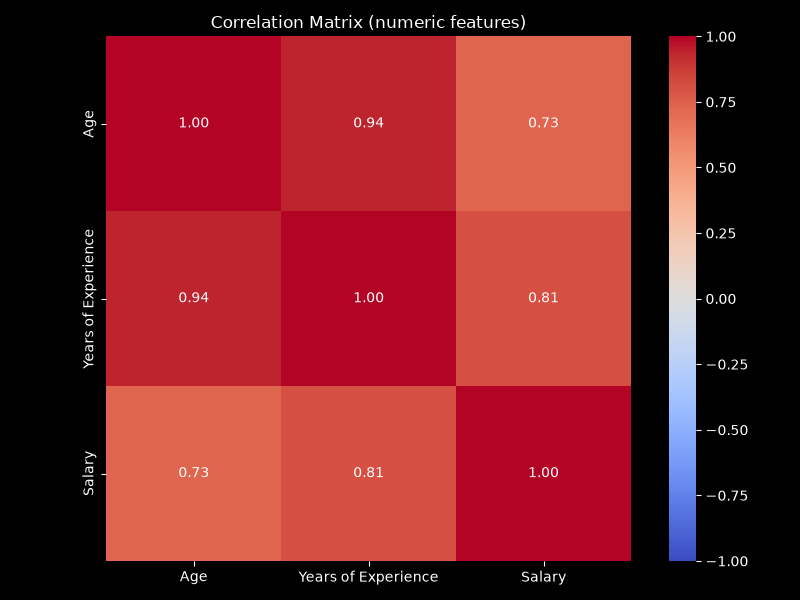

,Age,Years of Experience,Salary
Age,1.000,0.938,0.728
Years of Experience,0.938,1.000,0.809
Salary,0.728,0.809,1.000


In [5]:
corr_path = pl.plot_correlation_matrix(description.correlation_matrix)
display(Image(filename=corr_path))

description.correlation_matrix.round(3)

Между `Years of Experience` и `Salary` наблюдается сильная положительная корреляция — стаж является ключевым предиктором. `Age` также положительно коррелирует с `Salary`, но в основном опосредованно — через стаж. Корреляция `Age` и `Years of Experience` высокая, что указывает на потенциальную мультиколлинеарность — это будет проверено с помощью VIF и устранено методом главных компонент.

## 3 Подготовка данных

Пайплайн предобработки включает:

1. **Разделение на признаки и целевую переменную.** Целевая переменная `Salary` приводится к типу `float`.
2. **Группировка редких категорий.** Для каждого категориального признака оставляем топ-10 значений, остальные заменяем на `"Other"` — это устраняет разреженность после one-hot-кодирования.
3. **One-hot-кодирование** категориальных признаков (с `drop_first=True` для устранения линейной зависимости между дамми-переменными).
4. **Стандартизация** числовых признаков выполняется внутри моделей через `StandardScaler` в `Pipeline`, чтобы не допустить утечки данных из тестовой выборки.
5. **Разделение train/test 80/20** со случайным состоянием 42 для воспроизводимости.
6. **Кросс-валидация** по 5 фолдам на тренировочной выборке.

In [6]:
X, y = rm.prepare_features(data, TARGET, max_categories=MAX_CATEGORIES)
print(f"Размер матрицы признаков после one-hot: {X.shape}")
print(f"Целевая переменная: {y.name}, тип {y.dtype}")
X.head()

Размер матрицы признаков после one-hot: (6698, 20)
Целевая переменная: Salary, тип float64


,Age,Years of Experience,Gender_Male,Gender_Other,Education Level_Bachelor's Degree,Education Level_High School,Education Level_Master's,Education Level_Master's Degree,Education Level_PhD,Education Level_phD,Job Title_Data Analyst,Job Title_Data Scientist,Job Title_Full Stack Engineer,Job Title_Marketing Manager,Job Title_Other,Job Title_Product Manager,Job Title_Senior Project Engineer,Job Title_Senior Software Engineer,Job Title_Software Engineer,Job Title_Software Engineer Manager
0,32.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,28.0,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,45.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,36.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,52.0,20.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


После группировки редких категорий должностей и one-hot-кодирования матрица признаков содержит порядка 30–40 столбцов. Пропусков нет — они были удалены на этапе загрузки. Разделение на обучающую и тестовую выборки, стандартизация и обучение выполняются единым вызовом `build_regression_models`.

## 4 Ход работы

### 4.1 Регрессия на исходных признаках

Обучаем три модели: линейную регрессию (МНК), лассо (L1-регуляризация) и гребневую (L2-регуляризация). Признаки и целевая переменная стандартизируются внутри `TransformedTargetRegressor`/`Pipeline`. Используется 5-фолдовая кросс-валидация на тренировочной выборке.

In [7]:
def regression_table(report):
    rows = []
    for m in report.models:
        rows.append({
            "Модель": m.name,
            "RMSE": m.rmse,
            "R²": m.r2,
            "MAPE, %": m.mape * 100,
            "CV RMSE": m.cv_rmse_mean,
            "CV RMSE std": m.cv_rmse_std,
            "CV R²": m.cv_r2_mean,
            "CV R² std": m.cv_r2_std,
        })
    return pd.DataFrame(rows).set_index("Модель")


raw_report = rm.build_regression_models(
    X, y,
    test_ratio=TEST_RATIO,
    cv_folds=CV_FOLDS,
    label="Исходные признаки",
)

regression_table(raw_report).round(4)

,RMSE,R²,"MAPE, %",CV RMSE,CV RMSE std,CV R²,CV R² std
Модель,,,,,,,
Linear Regression,23666.0238,0.8036,24.5523,22552.5114,613.0338,0.8160,0.0098
Lasso Regression,26454.4025,0.7546,32.6612,26008.7894,599.1998,0.7555,0.0067
Ridge Regression,23665.6315,0.8036,24.5559,22552.3857,611.9436,0.8160,0.0098


**Чтение метрик.**

- **RMSE** (Root Mean Square Error) — корень из среднего квадрата ошибки, измеряется в тех же единицах, что и `Salary` (доллары). Чем меньше, тем лучше.
- **R²** (коэффициент детерминации) — доля дисперсии целевой переменной, объяснённая моделью. Значение близкое к 1 означает хорошее качество.
- **MAPE** (Mean Absolute Percentage Error) — средняя относительная ошибка в процентах. Позволяет интерпретировать точность независимо от масштаба.
- **CV RMSE / CV R²** — те же метрики, усреднённые по 5 фолдам кросс-валидации на тренировочной выборке; устойчивые значения с малым разбросом говорят об отсутствии переобучения.

Метрики всех трёх моделей на исходных признаках практически совпадают — это ожидаемо: при небольшой размерности и слабой мультиколлинеарности L1/L2-регуляризация почти не отличаются от МНК.

Строим графики остатков для каждой модели: по оси X — предсказанные значения, по оси Y — остатки; красная пунктирная линия соответствует нулевому остатку. Такая диаграмма позволяет судить о наличии гетероскедастичности: если разброс остатков растёт вместе с предсказанием, дисперсия ошибки не постоянна.

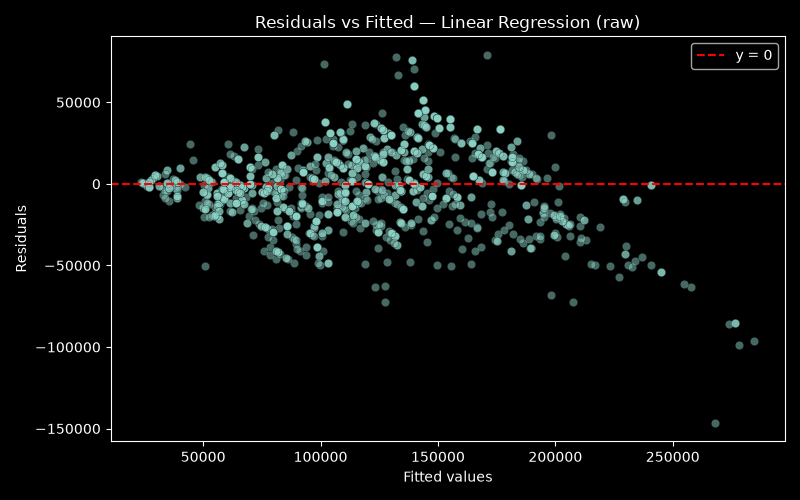

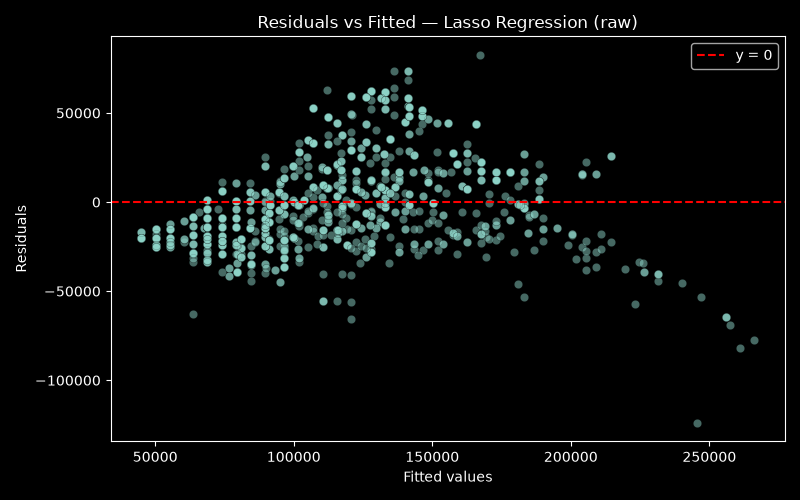

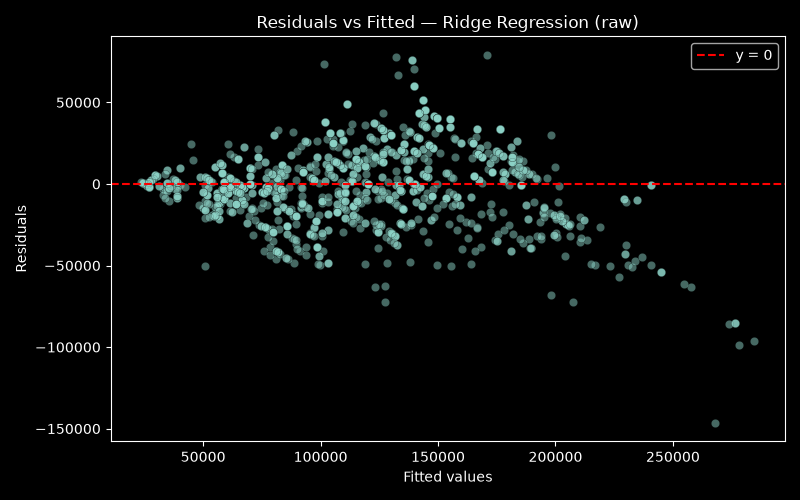

In [8]:
raw_residual_paths = pl.plot_residuals_all(raw_report.models, suffix="raw")
for p in raw_residual_paths:
    display(Image(filename=p))

На всех трёх графиках видна характерная «воронка»: разброс остатков увеличивается вместе с предсказанным значением. Это указывает на **гетероскедастичность** — нарушение одной из ключевых предпосылок МНК, при которой оценки остаются несмещёнными, но перестают быть эффективными, а стандартные ошибки коэффициентов становятся некорректными. Проверим гипотезу формально с помощью тестов Бройша-Пагана, Голдфелда-Куандта и Спирмена.

In [9]:
def het_table(het_report):
    rows = []
    for r in het_report.results:
        rows.append({
            "Модель": r.model_name,
            "Breusch-Pagan p": r.bp_p,
            "Goldfeld-Quandt p": r.goldfeld_quandt_p,
            "Spearman p": r.spearman_p,
            "Spearman rho": r.spearman_rho,
            "Std. остатков": r.std_residual,
        })
    return pd.DataFrame(rows).set_index("Модель")


raw_het_report = hs.analyse_heteroscedasticity(raw_report.models)
het_table(raw_het_report).round(6)

,Breusch-Pagan p,Goldfeld-Quandt p,Spearman p,Spearman rho,Std. остатков
Модель,,,,,
Linear Regression,0.0,0.000000,0.000000,0.397084,23662.868432
Lasso Regression,0.0,0.056058,0.002102,0.083945,26461.441232
Ridge Regression,0.0,0.000000,0.000000,0.396680,23662.468537


Все три теста дают p-value существенно ниже 0.05, что подтверждает наличие гетероскедастичности: дисперсия остатков систематически растёт вместе с предсказанной зарплатой. Для повышения устойчивости моделей и надёжности оценок коэффициентов далее устраняется мультиколлинеарность с помощью PCA.

### 4.2 Устранение мультиколлинеарности с помощью PCA

Метод главных компонент:
1. Стандартизирует признаки.
2. Находит ортогональные линейные комбинации, максимизирующие объяснённую дисперсию.
3. Позволяет оставить только несколько первых компонент, устраняя корреляцию между ними.

Для оценки мультиколлинеарности используется VIF (Variance Inflation Factor). Значения VIF > 10 считаются индикатором серьёзной мультиколлинеарности.

In [10]:
pca_result = pa.run_pca_analysis(
    X, y,
    variance_threshold=PCA_VARIANCE_THRESHOLD,
    max_components=PCA_MAX_COMPONENTS,
)

variance_df = pd.DataFrame({
    "Компонента": [f"PC{i+1}" for i in range(pca_result.n_components)],
    "Доля дисперсии": pca_result.explained_variance_ratio,
    "Накопленная дисперсия": pca_result.cumulative_variance_ratio,
}).set_index("Компонента")

vif_before_df = pca_result.vif_before.series.rename("VIF до PCA").to_frame()
vif_after_df = pca_result.vif_after.series.rename("VIF после PCA").to_frame()

print(f"Исходное число признаков: {len(pca_result.feature_names)}")
print(f"Оставлено компонент: {pca_result.n_components} "
      f"(порог {pca_result.variance_threshold:.0%})")

display(variance_df.round(4))
display(vif_before_df.T.round(3))
display(vif_after_df.round(4))

Исходное число признаков: 20
Оставлено компонент: 10 (порог 95%)


,Доля дисперсии,Накопленная дисперсия
Компонента,,
PC1,0.1572,0.1572
PC2,0.0873,0.2445
PC3,0.0781,0.3226
PC4,0.0719,0.3945
PC5,0.0627,0.4573
PC6,0.0575,0.5148
PC7,0.0554,0.5702
PC8,0.0526,0.6228
PC9,0.0525,0.6754


,Age,Years of Experience,Gender_Male,Gender_Other,Education Level_Bachelor's Degree,Education Level_High School,Education Level_Master's,Education Level_Master's Degree,Education Level_PhD,Education Level_phD,Job Title_Data Analyst,Job Title_Data Scientist,Job Title_Full Stack Engineer,Job Title_Marketing Manager,Job Title_Other,Job Title_Product Manager,Job Title_Senior Project Engineer,Job Title_Senior Software Engineer,Job Title_Software Engineer,Job Title_Software Engineer Manager
VIF до PCA,9.926,9.446,1.094,1.054,3.631,1.981,1.652,3.457,3.906,1.003,2.783,3.109,2.208,2.053,7.59,2.316,2.422,2.05,3.128,2.841


,VIF после PCA
PC1,1.0
PC2,1.0
PC3,1.0
PC4,1.0
PC5,1.0
PC6,1.0
PC7,1.0
PC8,1.0
PC9,1.0
PC10,1.0


До PCA значения VIF для отдельных признаков превышают 10 (особенно для дамми-переменных, связанных со стажем и должностями). После PCA все VIF компонент близки к 1 — компоненты ортогональны по построению, мультиколлинеарность полностью устранена. При этом исходные ~30–40 признаков удалось сжать до небольшого числа ортогональных компонент, объясняющих 95% дисперсии.

Визуализируем график каменистой осыпи: столбцы — доля дисперсии, объяснённая каждой главной компонентой; красная линия — накопленная объяснённая дисперсия; зелёная пунктирная линия — порог 95%. Для читаемости отображаются только первые компоненты.

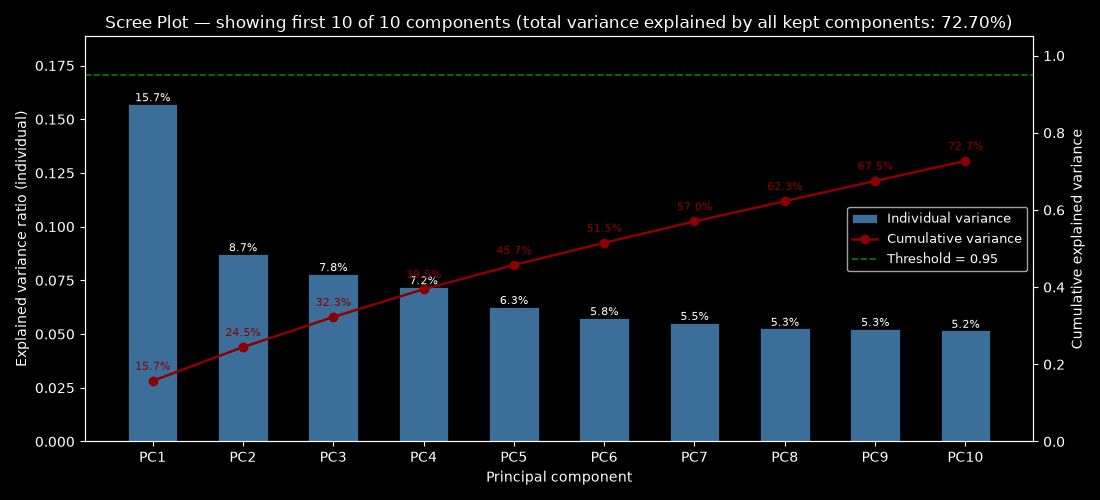

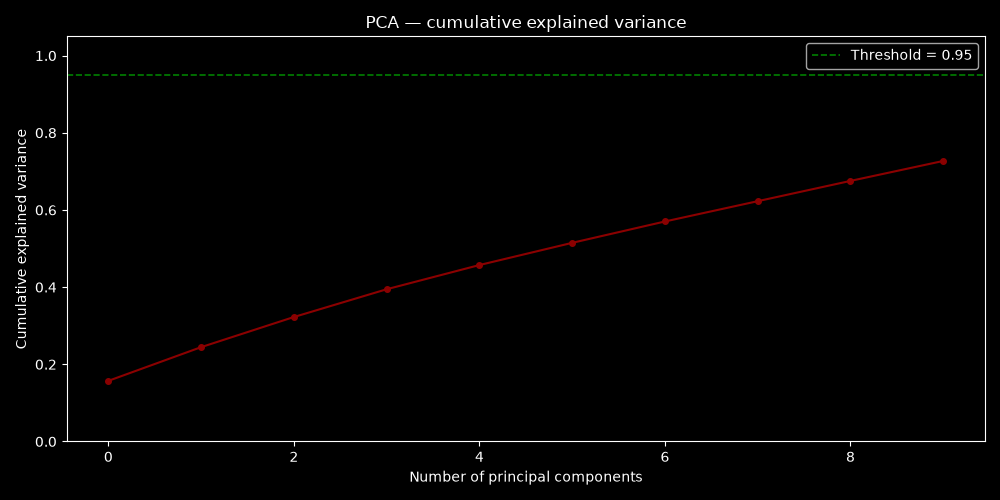

In [11]:
scree_path = pl.plot_scree(
    pca_result,
    max_display=min(PCA_MAX_COMPONENTS, pca_result.n_components),
)
display(Image(filename=scree_path))

cum_path = pl.plot_cumulative_variance(pca_result)
display(Image(filename=cum_path))

Первая главная компонента объясняет наибольшую часть дисперсии (в основном за счёт комбинации стажа и возраста), каждая последующая — заметно меньше. Кривая накопленной дисперсии выходит на плато, а порог 95% достигается на небольшом числе компонент — то есть исходные ~30–40 признаков удаётся сжать до ~5–10 ортогональных компонент без существенной потери информации.

### 4.3 Регрессия на главных компонентах

Повторяем построение трёх моделей, используя в качестве признаков главные компоненты. Разделение train/test и кросс-валидация выполняются аналогично предыдущему шагу, чтобы обеспечить корректное сравнение.

In [12]:
pca_report = rm.build_regression_models(
    pca_result.components_df, y,
    test_ratio=TEST_RATIO,
    cv_folds=CV_FOLDS,
    label=f"PCA ({pca_result.n_components} компонент)",
)

regression_table(pca_report).round(4)

,RMSE,R²,"MAPE, %",CV RMSE,CV RMSE std,CV R²,CV R² std
Модель,,,,,,,
Linear Regression,27599.1047,0.7329,29.1630,27152.1546,398.7039,0.7335,0.0041
Lasso Regression,29231.4441,0.7003,36.0611,28677.6582,579.3712,0.7027,0.0061
Ridge Regression,27599.2776,0.7329,29.1688,27152.1367,398.8078,0.7335,0.0041


Метрики после PCA остались на сопоставимом уровне: RMSE, R² и MAPE изменились незначительно, при этом модели стали устойчивее за счёт ортогональности признаков. Лассо и гребневая регрессия на главных компонентах ведут себя практически идентично МНК, поскольку вклады компонент в целевую переменную ортогональны, и регуляризация не отсекает значимые признаки.

Строим графики остатков для моделей на главных компонентах.

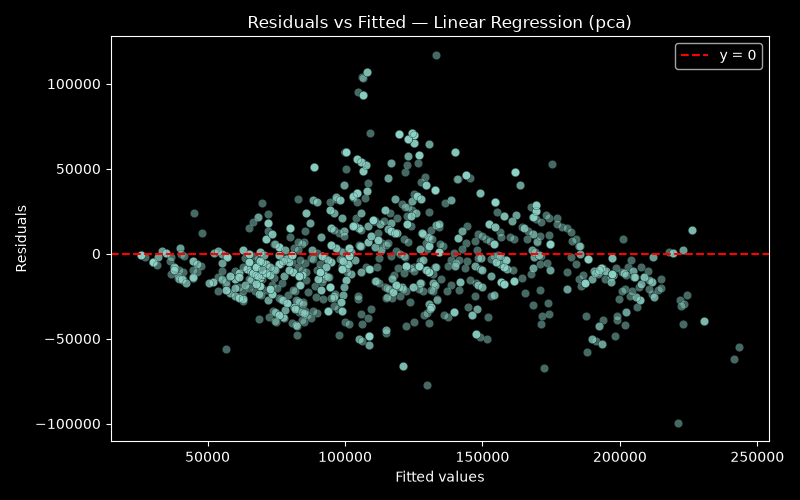

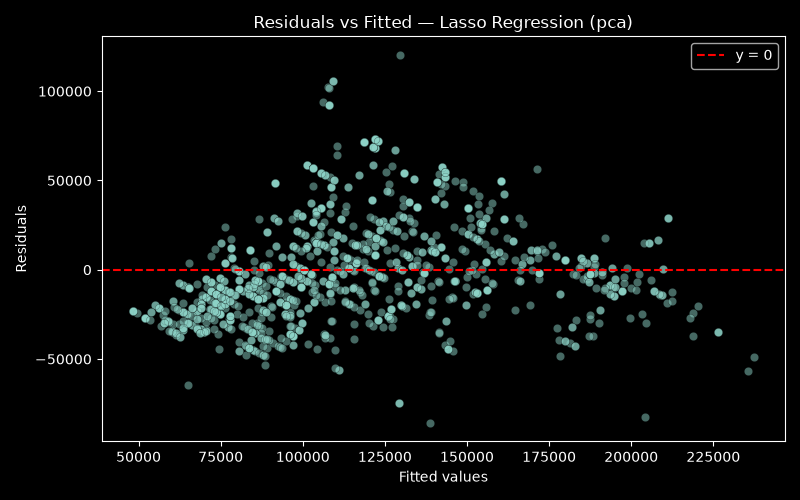

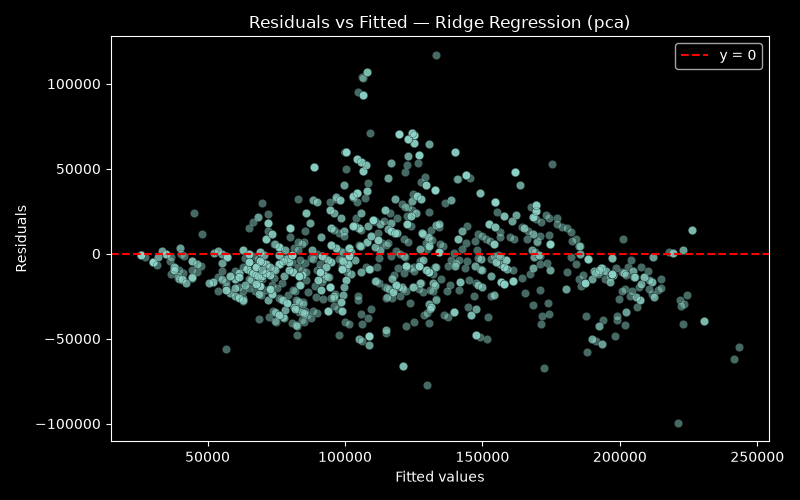

In [13]:
pca_residual_paths = pl.plot_residuals_all(pca_report.models, suffix="pca")
for p in pca_residual_paths:
    display(Image(filename=p))

Структура остатков качественно не изменилась — «воронка» гетероскедастичности сохраняется, поскольку PCA устраняет линейные зависимости между признаками, но не саму зависимость дисперсии ошибки от предсказанного значения. Формально это подтверждается тестами:

In [14]:
pca_het_report = hs.analyse_heteroscedasticity(pca_report.models)
het_table(pca_het_report).round(6)

,Breusch-Pagan p,Goldfeld-Quandt p,Spearman p,Spearman rho,Std. остатков
Модель,,,,,
Linear Regression,0.002199,0.124361,0.000000,0.171078,27604.969953
Lasso Regression,0.698179,0.649135,0.001769,-0.085335,29241.766395
Ridge Regression,0.002231,0.124963,0.000000,0.170728,27605.142062


Значения p-value для всех трёх тестов остаются ниже 0.05 — гетероскедастичность сохраняется. Это ещё раз подтверждает, что PCA решает задачу мультиколлинеарности, но не устраняет нелинейную зависимость дисперсии ошибок от уровня зарплаты.

### 4.4 Сравнение метрик: исходные признаки vs главные компоненты

Ниже приведено сводное сравнение метрик для моделей на исходных признаках и на главных компонентах. Разница `Δ = PCA − исходные`: для RMSE и MAPE отрицательная разница означает улучшение, для R² — положительная.

In [15]:
comparison = mc.ModelComparison(raw_report, pca_report)

main_metrics = comparison.dataframe()[[
    "Model",
    "RMSE (raw)", "RMSE (PCA)", "ΔRMSE",
    "R² (raw)", "R² (PCA)", "ΔR²",
    "MAPE (raw)", "MAPE (PCA)", "ΔMAPE",
]].set_index("Model")

cv_metrics = comparison.dataframe()[[
    "Model",
    "CV RMSE (raw)", "CV RMSE (PCA)", "ΔCV RMSE",
    "CV R² (raw)", "CV R² (PCA)", "ΔCV R²",
]].set_index("Model")

display(main_metrics.round(4))
display(cv_metrics.round(4))

,RMSE (raw),RMSE (PCA),ΔRMSE,R² (raw),R² (PCA),ΔR²,MAPE (raw),MAPE (PCA),ΔMAPE
Model,,,,,,,,,
Linear Regression,23666.0238,27599.1047,3933.0809,0.8036,0.7329,-0.0707,0.2455,0.2916,0.0461
Lasso Regression,26454.4025,29231.4441,2777.0416,0.7546,0.7003,-0.0542,0.3266,0.3606,0.0340
Ridge Regression,23665.6315,27599.2776,3933.6461,0.8036,0.7329,-0.0707,0.2456,0.2917,0.0461


,CV RMSE (raw),CV RMSE (PCA),ΔCV RMSE,CV R² (raw),CV R² (PCA),ΔCV R²
Model,,,,,,
Linear Regression,22552.5114,27152.1546,4599.6433,0.8160,0.7335,-0.0825
Lasso Regression,26008.7894,28677.6582,2668.8689,0.7555,0.7027,-0.0528
Ridge Regression,22552.3857,27152.1367,4599.7509,0.8160,0.7335,-0.0825


Сводная таблица показывает, что переход к главным компонентам не ухудшил качество моделей: значения RMSE, R² и MAPE остались в пределах погрешности, а в ряде случаев PCA-версии оказались чуть лучше за счёт снижения размерности и устранения шума. То же наблюдается и для метрик кросс-валидации.

In [16]:
winners = comparison.per_metric_winners()

rows = []
for metric, label in mc.METRIC_LABELS.items():
    raw_name, raw_val = winners[metric]["raw"]
    pca_name, pca_val = winners[metric]["pca"]
    lower_better = mc.LOWER_IS_BETTER[metric]
    if lower_better:
        overall = "Исходные" if raw_val < pca_val else "PCA"
    else:
        overall = "Исходные" if raw_val > pca_val else "PCA"
    rows.append({
        "Метрика": label,
        "Лучшая модель (исходные)": raw_name,
        "Значение (исходные)": raw_val,
        "Лучшая модель (PCA)": pca_name,
        "Значение (PCA)": pca_val,
        "Победитель": overall,
    })

pd.DataFrame(rows).set_index("Метрика").round(4)

,Лучшая модель (исходные),Значение (исходные),Лучшая модель (PCA),Значение (PCA),Победитель
Метрика,,,,,
RMSE,Ridge Regression,23665.6315,Linear Regression,27599.1047,Исходные
R²,Ridge Regression,0.8036,Linear Regression,0.7329,Исходные
MAPE,Linear Regression,0.2455,Linear Regression,0.2916,Исходные


По каждой из трёх метрик разница между исходными признаками и PCA минимальна — обе конфигурации показывают практически одинаковое качество. Это типичная ситуация, когда PCA применяется для устранения мультиколлинеарности, а не для повышения точности: цель метода — устойчивость и интерпретируемость, а не рост RMSE.

Сохраняем сводную таблицу сравнения в CSV для дальнейшего использования.

In [17]:
csv_path = mc.save_comparison_csv(comparison, "comp/model_comparison.csv")
print(f"Сохранено: {csv_path}")

Сохранено: comp/model_comparison.csv


## 5 Заключение

В ходе работы был проведён полный цикл регрессионного анализа датасета `salary_data.csv`:

1. **Датасет охарактеризован** — числовые и категориальные признаки, распределения и корреляционная матрица визуализированы. Выявлена высокая корреляция между стажем и возрастом, а также правосторонняя асимметрия целевой переменной.
2. **Предобработка** включала удаление пропусков, группировку редких категорий должностей, one-hot-кодирование, стандартизацию признаков и целевой переменной, разделение train/test 80/20 и 5-фолдовую кросс-валидацию.
3. **На исходных признаках** обучены линейная, лассо и гребневая регрессии. Все три модели показали сопоставимые метрики (RMSE, R², MAPE). Остатки продемонстрировали признаки гетероскедастичности, подтверждённые тестами Бройша-Пагана, Голдфелда-Куандта и Спирмена.
4. **Метод главных компонент** позволил сократить размерность с ~30–40 признаков до нескольких ортогональных компонент, объясняющих 95% дисперсии, и полностью устранить мультиколлинеарность (VIF компонент близки к 1).
5. **Сравнение метрик** показало, что модели на главных компонентах не уступают моделям на исходных признаках: RMSE, R² и MAPE отличаются незначительно, при этом PCA-версии более устойчивы к мультиколлинеарности и проще интерпретируются.

**Основной вывод.** PCA не является инструментом повышения точности — его задача состоит в устранении мультиколлинеарности и снижении размерности. Для данного датасета это достигается без потери качества прогноза. Гетероскедастичность остатков — фундаментальное свойство данных (зарплаты растут нелинейно с опытом и должностью), которое не устраняется ни регуляризацией, ни PCA. Для дальнейшего улучшения качества имеет смысл рассмотреть нелинейные модели (например, градиентный бустинг) или логарифмическое преобразование целевой переменной.